# A guide Portfolio Optimization Environment

This notebook aims to provide an example of using PortfolioOptimizationEnv (or POE) to train a reinforcement learning model that learns to solve the portfolio optimization problem.

In this document, we will reproduce a famous architecture called EIIE (ensemble of identical independent evaluators), introduced in the following paper:

- Zhengyao Jiang, Dixing Xu, & Jinjun Liang. (2017). A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem. https://doi.org/10.48550/arXiv.1706.10059.

It's advisable to read it to understand the algorithm implemented in this notebook.

### Note
If you're using this environment, consider citing the following paper (in adittion to FinRL references):

- Caio Costa, & Anna Costa (2023). POE: A General Portfolio Optimization Environment for FinRL. In *Anais do II Brazilian Workshop on Artificial Intelligence in Finance* (pp. 132–143). SBC. https://doi.org/10.5753/bwaif.2023.231144.

```
@inproceedings{bwaif,
 author = {Caio Costa and Anna Costa},
 title = {POE: A General Portfolio Optimization Environment for FinRL},
 booktitle = {Anais do II Brazilian Workshop on Artificial Intelligence in Finance},
 location = {João Pessoa/PB},
 year = {2023},
 keywords = {},
 issn = {0000-0000},
 pages = {132--143},
 publisher = {SBC},
 address = {Porto Alegre, RS, Brasil},
 doi = {10.5753/bwaif.2023.231144},
 url = {https://sol.sbc.org.br/index.php/bwaif/article/view/24959}
}

```

## Installation and imports

To run this notebook in google colab, uncomment the cells below.

In [ ]:
## install finrl library
# !sudo apt install swig
# !pip install git+https://github.com/AI4Finance-Foundation/FinRL.git

In [ ]:
## We also need to install quantstats, because the environment uses it to plot graphs
# !pip install quantstats

In [1]:
## Hide matplotlib warnings
# import warnings
# warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').disabled = True

#### Import the necessary code libraries

In [2]:
import torch

from sklearn.preprocessing import MaxAbsScaler

from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import GroupByScaler
from finrl.meta.env_portfolio_optimization.env_portfolio_optimization import PortfolioOptimizationEnv
from finrl.agents.portfolio_optimization.models import DRLAgent
from finrl.agents.portfolio_optimization.architectures_raw import EIIE

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Fetch data

In his paper, *Jiang et al* creates a portfolio composed by the top-11 cryptocurrencies based on 30-days volume. Since it's not specified when this classification was done, it's difficult to reproduce, so we will use a similar approach in the Brazillian stock market:

- We select top-10 stocks from Brazillian stock market;
- For simplicity, we disconsider stocks that have missing data for the days in period 2011-01-01 to 2019-12-31 (9 years);

In [3]:
TOP_BRL = [
        "601012.SS",
        "600887.SS",
        "600030.SS",   
        "600031.SS",
        "600036.SS",        
        "600276.SS", 
        "600519.SS", 
        "601318.SS", 
        "600703.SS", 
        "601166.SS", 
    ]

In [4]:
%env HTTP_PROXY=http://127.0.0.1:7897
%env HTTPS_PROXY=http://127.0.0.1:7897

env: HTTP_PROXY=http://127.0.0.1:7897
env: HTTPS_PROXY=http://127.0.0.1:7897


In [46]:
print(len(TOP_BRL))

portfolio_raw_df = YahooDownloader(start_date = '2014-01-01',
                                end_date = '2025-12-31',
                                ticker_list = TOP_BRL).fetch_data()
portfolio_raw_df

10


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (29160, 8)


Price,date,close,high,low,open,volume,tic,day
0,2014-01-02,9.274567,9.348232,9.193533,9.289300,71936303,600030.SS,3
1,2014-01-02,5.264814,5.289570,5.248310,5.289570,9087799,600031.SS,3
2,2014-01-02,6.447872,6.525991,6.411817,6.513973,53256490,600036.SS,3
3,2014-01-02,8.174830,8.308776,7.932056,7.950891,36239316,600276.SS,3
4,2014-01-02,80.822762,82.112281,80.578972,82.112281,2659175,600519.SS,3
...,...,...,...,...,...,...,...,...
29155,2025-12-30,14.160000,14.420000,14.100000,14.320000,74844398,600703.SS,1
29156,2025-12-30,28.690001,28.900000,28.610001,28.760000,39049803,600887.SS,1
29157,2025-12-30,18.440001,18.750000,18.400000,18.549999,98250988,601012.SS,1
29158,2025-12-30,20.475147,20.795526,20.455730,20.727567,67534398,601166.SS,1


In [47]:
portfolio_raw_df.groupby("tic").count()

Price,date,close,high,low,open,volume,day
tic,,,,,,,
600030.SS,2916,2916,2916,2916,2916,2916,2916
600031.SS,2916,2916,2916,2916,2916,2916,2916
600036.SS,2916,2916,2916,2916,2916,2916,2916
600276.SS,2916,2916,2916,2916,2916,2916,2916
600519.SS,2916,2916,2916,2916,2916,2916,2916
600703.SS,2916,2916,2916,2916,2916,2916,2916
600887.SS,2916,2916,2916,2916,2916,2916,2916
601012.SS,2916,2916,2916,2916,2916,2916,2916
601166.SS,2916,2916,2916,2916,2916,2916,2916


### Normalize Data

We normalize the data dividing the time series of each stock by its maximum value, so that the dataframe contains values between 0 and 1.

In [48]:
portfolio_norm_df = GroupByScaler(by="tic", scaler=MaxAbsScaler).fit_transform(portfolio_raw_df)
portfolio_norm_df

c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.04898638 0.06069891 0.07574341 ... 0.0962567  0.06174419 0.05817843]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(
c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.75 1.   0.   ... 1.   0.   0.25]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(


Price,date,close,high,low,open,volume,tic,day
0,2014-01-02,0.273184,0.263205,0.273384,0.261546,0.048986,600030.SS,0.75
1,2014-01-02,0.122140,0.116932,0.124431,0.118178,0.010523,600031.SS,0.75
2,2014-01-02,0.141247,0.141939,0.142627,0.143405,0.056458,600036.SS,0.75
3,2014-01-02,0.086874,0.086892,0.086443,0.083838,0.186574,600276.SS,0.75
4,2014-01-02,0.035453,0.035650,0.036996,0.036199,0.083608,600519.SS,0.75
...,...,...,...,...,...,...,...,...
29155,2025-12-30,0.318843,0.324698,0.332674,0.326885,0.178415,600703.SS,0.25
29156,2025-12-30,0.666377,0.669184,0.694480,0.670468,0.071503,600887.SS,0.25
29157,2025-12-30,0.265548,0.261909,0.268890,0.267666,0.099014,601012.SS,0.25
29158,2025-12-30,0.838902,0.841650,0.844828,0.849582,0.049759,601166.SS,0.25


In [49]:
df_portfolio = portfolio_norm_df[["date", "tic", "close", "high", "low"]]

# 训练集：2014-2021
df_portfolio_train = df_portfolio[
    (df_portfolio["date"] >= "2014-01-01") & 
    (df_portfolio["date"] < "2022-01-01")
]

# 验证集：2022全年（从训练集末尾切出来）
df_portfolio_val = df_portfolio[
    (df_portfolio["date"] >= "2022-01-01") & 
    (df_portfolio["date"] < "2023-01-01")
]

# 测试集：2023-2025全年
df_portfolio_2023 = df_portfolio[
    (df_portfolio["date"] >= "2023-01-01") & 
    (df_portfolio["date"] < "2024-01-01")
]

df_portfolio_2024 = df_portfolio[
    (df_portfolio["date"] >= "2024-01-01") & 
    (df_portfolio["date"] < "2025-01-01")
]

df_portfolio_2025 = df_portfolio[
    (df_portfolio["date"] >= "2025-01-01") & 
    (df_portfolio["date"] < "2026-01-01")
]

### Instantiate Environment

Using the `PortfolioOptimizationEnv`, it's easy to instantiate a portfolio optimization environment for reinforcement learning agents. In the example below, we use the dataframe created before to start an environment.

In [50]:
environment = PortfolioOptimizationEnv(
        df_portfolio_train,
        initial_amount=100000,
        comission_fee_pct=0.0020,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
    )

# 验证集环境（参数与训练环境保持一致）
environment_val = PortfolioOptimizationEnv(
        df_portfolio_val,
        initial_amount=100000,
        comission_fee_pct=0.0020,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
)


### Instantiate Model

Now, we can instantiate the model using FinRL API. In this example, we are going to use the EIIE architecture introduced by Jiang et. al.

:exclamation: **Note:** Remember to set the architecture's `time_window` parameter with the same value of the environment's `time_window`.

In [51]:
# set PolicyGradient parameters
model_kwargs = {
    "lr": 0.001,
    "policy": EIIE,
}

# here, we can set EIIE's parameters
policy_kwargs = {
    "k_size": 3,
    "time_window": 50,
}

model = DRLAgent(environment).get_model("pg", device, model_kwargs, policy_kwargs)

### Train Model

In [ ]:
# DRLAgent.train_model(model, episodes=5)

  0%|          | 0/5 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 362680.375
Final accumulative portfolio value: 3.62680375
Maximum DrawDown: -0.4418092137148848
Sharpe ratio: 0.7919597722519486


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 20%|██        | 1/5 [00:29<01:57, 29.25s/it]

Initial portfolio value:100000
Final portfolio value: 380711.59375
Final accumulative portfolio value: 3.8071159375
Maximum DrawDown: -0.44651977738695625
Sharpe ratio: 0.8175047971272136


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 40%|████      | 2/5 [01:02<01:35, 31.86s/it]

...

c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 60%|██████    | 3/5 [01:31<01:01, 30.53s/it]

Initial portfolio value:100000
Final portfolio value: 460556.9375
Final accumulative portfolio value: 4.605569375
Maximum DrawDown: -0.4662751129846948
Sharpe ratio: 0.9188314817649084


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 80%|████████  | 4/5 [02:00<00:29, 29.79s/it]

Initial portfolio value:100000
Final portfolio value: 505369.5625
Final accumulative portfolio value: 5.053695625
Maximum DrawDown: -0.4769448035171513
Sharpe ratio: 0.9641094580843963


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
100%|██████████| 5/5 [02:40<00:00, 32.05s/it]


In [52]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import copy

def calculate_sharpe(value_list, risk_free_rate=0, periods_per_year=252):
    """从组合净值序列计算年化 Sharpe Ratio（无风险利率默认2%）"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    if daily_returns.std() == 0:
        return 0.0
    excess = daily_returns.mean() - risk_free_rate / periods_per_year
    return (excess / daily_returns.std()) * np.sqrt(periods_per_year)

def calculate_metrics(value_list, risk_free_rate=0, periods_per_year=252):
    """计算完整指标：累计收益、年化收益、波动率、Sharpe、最大回撤、Calmar"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    
    total_return   = (values[-1] / values[0]) - 1
    n_days         = len(values) - 1
    annual_return  = (1 + total_return) ** (periods_per_year / n_days) - 1
    annual_vol     = daily_returns.std() * np.sqrt(periods_per_year)
    
    excess         = daily_returns.mean() - risk_free_rate / periods_per_year
    sharpe         = (excess / daily_returns.std()) * np.sqrt(periods_per_year) if daily_returns.std() != 0 else 0.0
    
    cumulative     = values / values[0]
    rolling_max    = np.maximum.accumulate(cumulative)
    drawdown       = (cumulative - rolling_max) / rolling_max
    max_drawdown   = drawdown.min()
    calmar         = annual_return / abs(max_drawdown) if max_drawdown != 0 else 0.0
    
    return {
        "累计收益":   round(total_return,  4),
        "年化收益":   round(annual_return, 4),
        "年化波动率": round(annual_vol,    4),
        "Sharpe":    round(sharpe,        4),
        "最大回撤":   round(max_drawdown,  4),
        "Calmar":    round(calmar,        4),
    }

# ── Early Stop 配置 ──────────────────────────────────────
MAX_EPISODES   = 20    # 最大训练轮数（可根据算力调整）
PATIENCE       = 3     # 连续多少轮验证集无改善则停止
SAVE_PATH      = "policy_EIIE_best.pt"

# ── 训练状态 ─────────────────────────────────────────────
best_val_sharpe  = -np.inf
best_episode     = 0
patience_counter = 0
history = {"val_sharpe": [], "val_return": []}

print(f"开始训练，最大轮数={MAX_EPISODES}，早停耐心值={PATIENCE}")
print("-" * 60)

for episode in range(1, MAX_EPISODES + 1):

    # 1. 训练一个 episode
    DRLAgent.train_model(model, episodes=1)

    # 2. 在验证集上评估
    DRLAgent.DRL_validation(model, environment_val, policy=model.train_policy)
    val_values = environment_val._asset_memory["final"]

    val_sharpe = calculate_sharpe(val_values)
    val_return = (val_values[-1] / val_values[0]) - 1
    history["val_sharpe"].append(val_sharpe)
    history["val_return"].append(val_return)

    print(f"第{episode:3d}轮 | 验证集 Sharpe: {val_sharpe:+.4f} | "
          f"验证集收益: {val_return:+.4f} | 历史最优: {best_val_sharpe:+.4f}（第{best_episode}轮）")

    # 3. 保存最优 checkpoint
    if val_sharpe > best_val_sharpe:
        best_val_sharpe  = val_sharpe
        best_episode     = episode
        patience_counter = 0
        torch.save(model.train_policy.state_dict(), SAVE_PATH)
        print(f"  ✓ 验证集 Sharpe 创新高，已保存最优模型 → {SAVE_PATH}")
    else:
        patience_counter += 1
        print(f"  耐心计数：{patience_counter}/{PATIENCE}")

    # 4. Early stopping
    if patience_counter >= PATIENCE:
        print(f"早停触发（第{episode}轮）")
        print(f"   最优轮次：第{best_episode}轮 | 验证集 Sharpe：{best_val_sharpe:.4f}")
        break

print("训练结束，加载最优权重...")
policy = EIIE(time_window=50, device=device)
policy.load_state_dict(torch.load(SAVE_PATH))
print(f"已加载最优模型（来自第{best_episode}轮，验证集 Sharpe = {best_val_sharpe:.4f}）")



开始训练，最大轮数=20，早停耐心值=3
------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 697841.6875
Final accumulative portfolio value: 6.978416875
Maximum DrawDown: -0.36392965015505263
Sharpe ratio: 1.2546783451483685


100%|██████████| 1/1 [00:26<00:00, 26.21s/it]


Initial portfolio value:100000
Final portfolio value: 93165.1015625
Final accumulative portfolio value: 0.931651015625
Maximum DrawDown: -0.21755016384134707
Sharpe ratio: -0.3526745065256951
第  1轮 | 验证集 Sharpe: -0.3545 | 验证集收益: -0.0683 | 历史最优: -inf（第0轮）
  ✓ 验证集 Sharpe 创新高，已保存最优模型 → policy_EIIE_best.pt


...

  0%|          | 0/1 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 5278720.0
Final accumulative portfolio value: 52.7872
Maximum DrawDown: -0.42301935176483774
Sharpe ratio: 1.7382915920083934


100%|██████████| 1/1 [00:25<00:00, 25.11s/it]


Initial portfolio value:100000
Final portfolio value: 102512.5625
Final accumulative portfolio value: 1.025125625
Maximum DrawDown: -0.23055801119772834
Sharpe ratio: 0.259838256410463
第 20轮 | 验证集 Sharpe: +0.2612 | 验证集收益: +0.0251 | 历史最优: +0.2574（第19轮）
  ✓ 验证集 Sharpe 创新高，已保存最优模型 → policy_EIIE_best.pt
训练结束，加载最优权重...
已加载最优模型（来自第20轮，验证集 Sharpe = 0.2612）


C:\Users\64954\AppData\Local\Temp\ipykernel_36588\308581018.py:95: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load(SAVE_PATH))


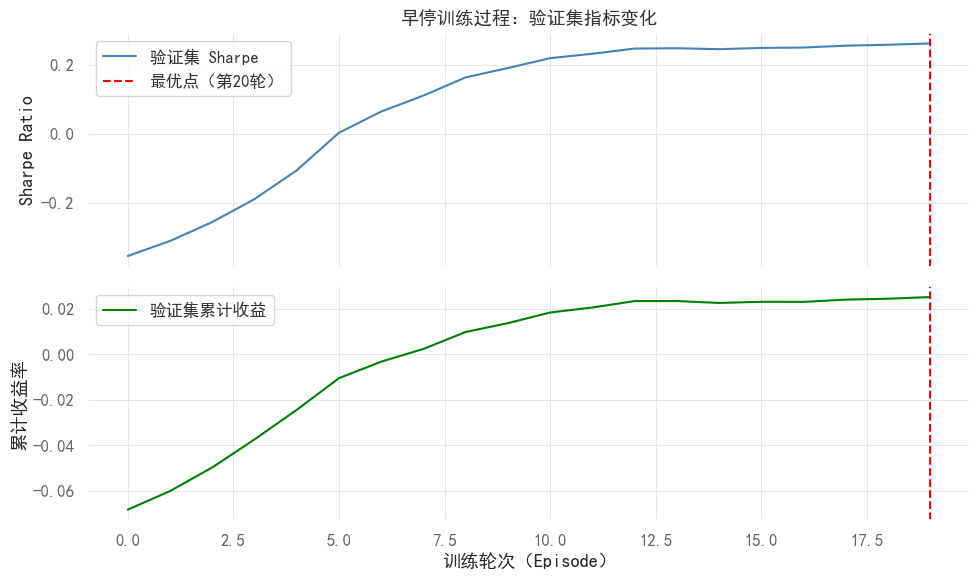

训练曲线已保存至 training_curve.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

output_dir = "raw_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示为方块的问题

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(history["val_sharpe"], color="steelblue", label="验证集 Sharpe")
ax1.axvline(best_episode - 1, color="red", linestyle="--", 
            label=f"最优点（第{best_episode}轮）")
ax1.set_ylabel("Sharpe Ratio")
ax1.legend()
ax1.set_title("早停训练过程：验证集指标变化")

ax2.plot(history["val_return"], color="green", label="验证集累计收益")
ax2.axvline(best_episode - 1, color="red", linestyle="--")
ax2.set_ylabel("累计收益率")
ax2.set_xlabel("训练轮次（Episode）")
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "training_curve.png"), dpi=150, bbox_inches="tight")
plt.show()
print("训练曲线已保存至 training_curve.png")

### Save Model

In [ ]:
# torch.save(model.train_policy.state_dict(), "policy_EIIE.pt")

## Test Model

### Instantiate different environments

Since we have three different periods of time, we need three different environments instantiated to simulate them.

In [54]:
environment_2023 = PortfolioOptimizationEnv(
    df_portfolio_2023,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2024 = PortfolioOptimizationEnv(
    df_portfolio_2024,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2025 = PortfolioOptimizationEnv(
    df_portfolio_2025,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

### Test EIIE architecture
Now, we can test the EIIE architecture in the three different test periods. It's important no note that, in this code, we load the saved policy even though it's not necessary just to show how to save and load your model.

In [ ]:
# import numpy as np

# def calculate_sharpe(value_list, risk_free_rate=0.0, periods_per_year=252):
#     """
#     从portfolio value序列计算年化Sharpe Ratio
#     value_list: 每日组合净值列表
#     """
#     values = np.array(value_list)
#     # 计算每日收益率
#     daily_returns = np.diff(values) / values[:-1]
    
#     if daily_returns.std() == 0:
#         return 0.0
    
#     # 年化Sharpe
#     sharpe = (daily_returns.mean() - risk_free_rate / periods_per_year) / daily_returns.std()
#     sharpe_annualized = sharpe * np.sqrt(periods_per_year)
#     return sharpe_annualized

In [55]:
import numpy as np

EIIE_results = {
    "training": environment._asset_memory["final"],
    "validation": {"value": list(environment_val._asset_memory["final"])},
    "2023": {},
    "2024": {},
    "2025": {}
}

# instantiate an architecture with the same arguments used in training
# and load with load_state_dict.
policy = EIIE(time_window=50, device=device)
policy.load_state_dict(torch.load("policy_EIIE_best.pt"))

for year, env in [("2023", environment_2023),
                  ("2024", environment_2024),
                  ("2025", environment_2025)]:
    DRLAgent.DRL_validation(model, env, policy=policy)
    values = env._asset_memory["final"]
    EIIE_results[year] = {
        "value":   list(values),
        "actions": np.array(env._actions_memory).copy(),
    }

C:\Users\64954\AppData\Local\Temp\ipykernel_36588\2216853319.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load("policy_EIIE_best.pt"))


Initial portfolio value:100000
Final portfolio value: 85130.4453125
Final accumulative portfolio value: 0.851304453125
Maximum DrawDown: -0.25836221711878127
Sharpe ratio: -0.9592476221746643
Initial portfolio value:100000
Final portfolio value: 93659.3203125
Final accumulative portfolio value: 0.936593203125
Maximum DrawDown: -0.24808079157601537
Sharpe ratio: -0.06807734534880541
Initial portfolio value:100000
Final portfolio value: 112138.9453125
Final accumulative portfolio value: 1.121389453125
Maximum DrawDown: -0.17844402671297588
Sharpe ratio: 0.6463051435653174


### Test Uniform Buy and Hold
For comparison, we will also test the performance of a uniform buy and hold strategy. In this strategy, the portfolio has no remaining cash and the same percentage of money is allocated in each asset.

In [56]:
EW_results = {
    "train": {},
    "2023": {},
    "2024": {},
    "2025": {}
}

PORTFOLIO_SIZE = len(TOP_BRL)

# train period
terminated = False
environment.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment.step(action)
EW_results["train"]["value"] = environment._asset_memory["final"]

# 2023
terminated = False
environment_2023.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2023.step(action)
EW_results["2023"]["value"] = environment_2023._asset_memory["final"]

# 2024
terminated = False
environment_2024.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2024.step(action)
EW_results["2024"]["value"] = environment_2024._asset_memory["final"]

# 2025
terminated = False
environment_2025.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2025.step(action)
EW_results["2025"]["value"] = environment_2025._asset_memory["final"]

Initial portfolio value:100000
Final portfolio value: 816536.3125
Final accumulative portfolio value: 8.165363125
Maximum DrawDown: -0.3947232722210038
Sharpe ratio: 1.2423344438329198
Initial portfolio value:100000
Final portfolio value: 90655.5546875
Final accumulative portfolio value: 0.906555546875
Maximum DrawDown: -0.18683307266542692
Sharpe ratio: -0.7532272199858674
Initial portfolio value:100000
Final portfolio value: 112132.3046875
Final accumulative portfolio value: 1.121323046875
Maximum DrawDown: -0.12743897001613524
Sharpe ratio: 0.7484957928415505
Initial portfolio value:100000
Final portfolio value: 110017.1484375
Final accumulative portfolio value: 1.100171484375
Maximum DrawDown: -0.08930781249999997
Sharpe ratio: 0.9742124311901129


### Plot graphics

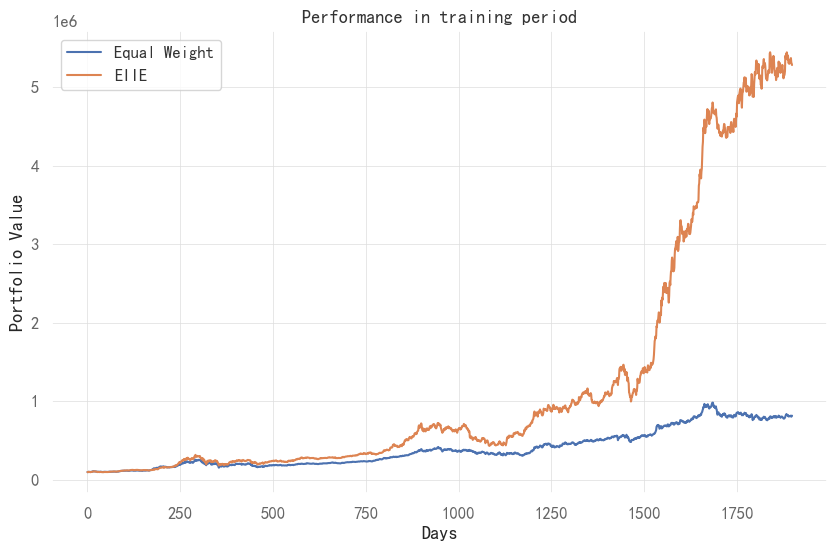

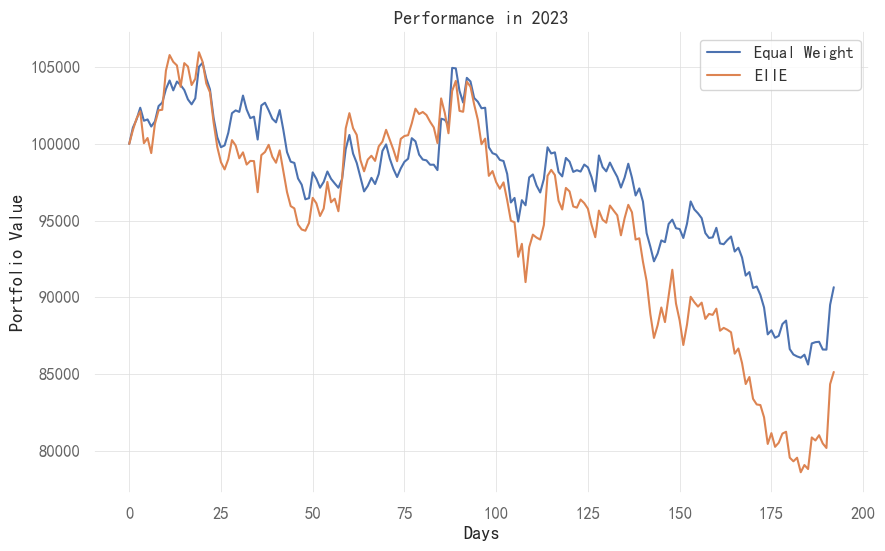

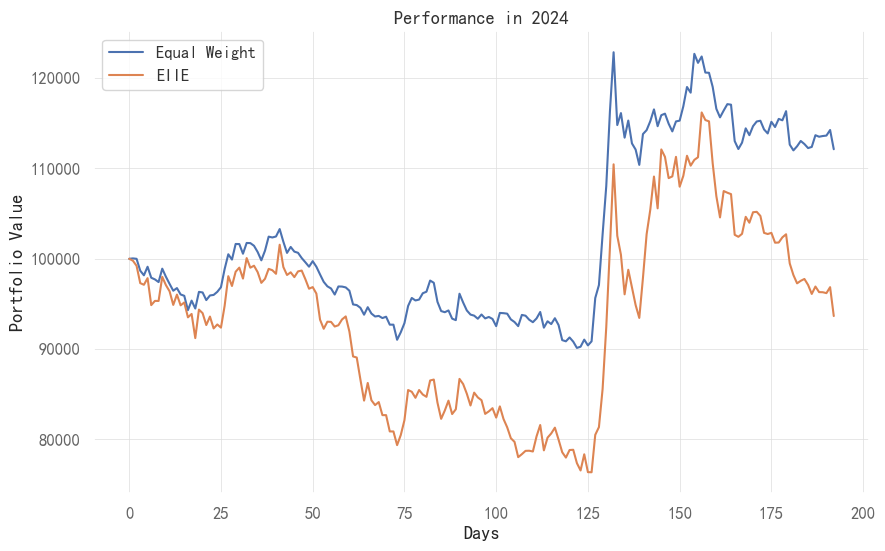

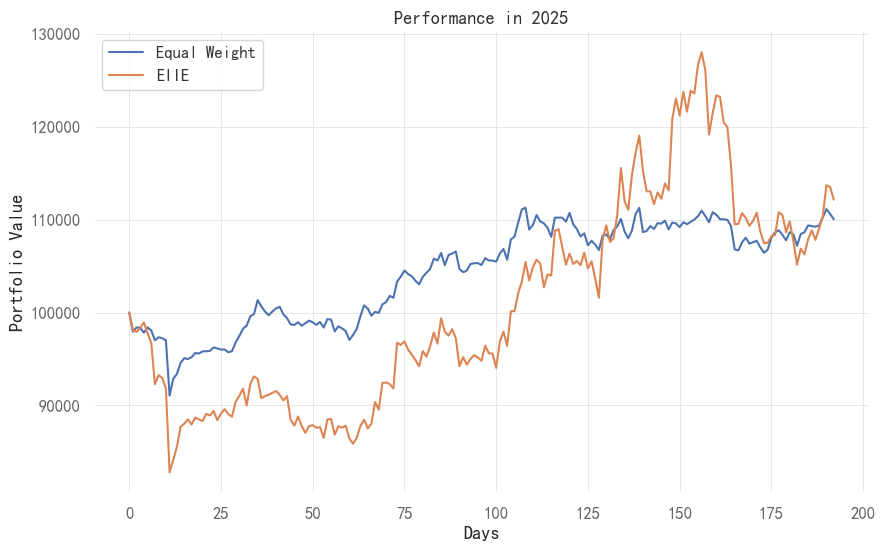

In [ ]:
import matplotlib.pyplot as plt
import os
%matplotlib inline 

output_dir = "raw_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.plot(EW_results["train"]["value"], label="Equal Weight")
plt.plot(EIIE_results["training"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in training period")
plt.legend()

plt.show()

plt.plot(EW_results["2023"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2023"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2023")
plt.legend()
plt.savefig(os.path.join(output_dir, "value_2023.png"), dpi=150, bbox_inches="tight")
plt.show()

plt.plot(EW_results["2024"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2024"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2024")
plt.legend()
plt.savefig(os.path.join(output_dir, "value_2024.png"), dpi=150, bbox_inches="tight")
plt.show()

plt.plot(EW_results["2025"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2025"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2025")
plt.legend()
plt.savefig(os.path.join(output_dir, "value_2025.png"), dpi=150, bbox_inches="tight")
plt.show()

We can see that the agent is able to learn a good policy but its performance is worse the more the test period advances into the future. To get a better performance in 2022, for example, the agent should probably be trained again using more recent data.

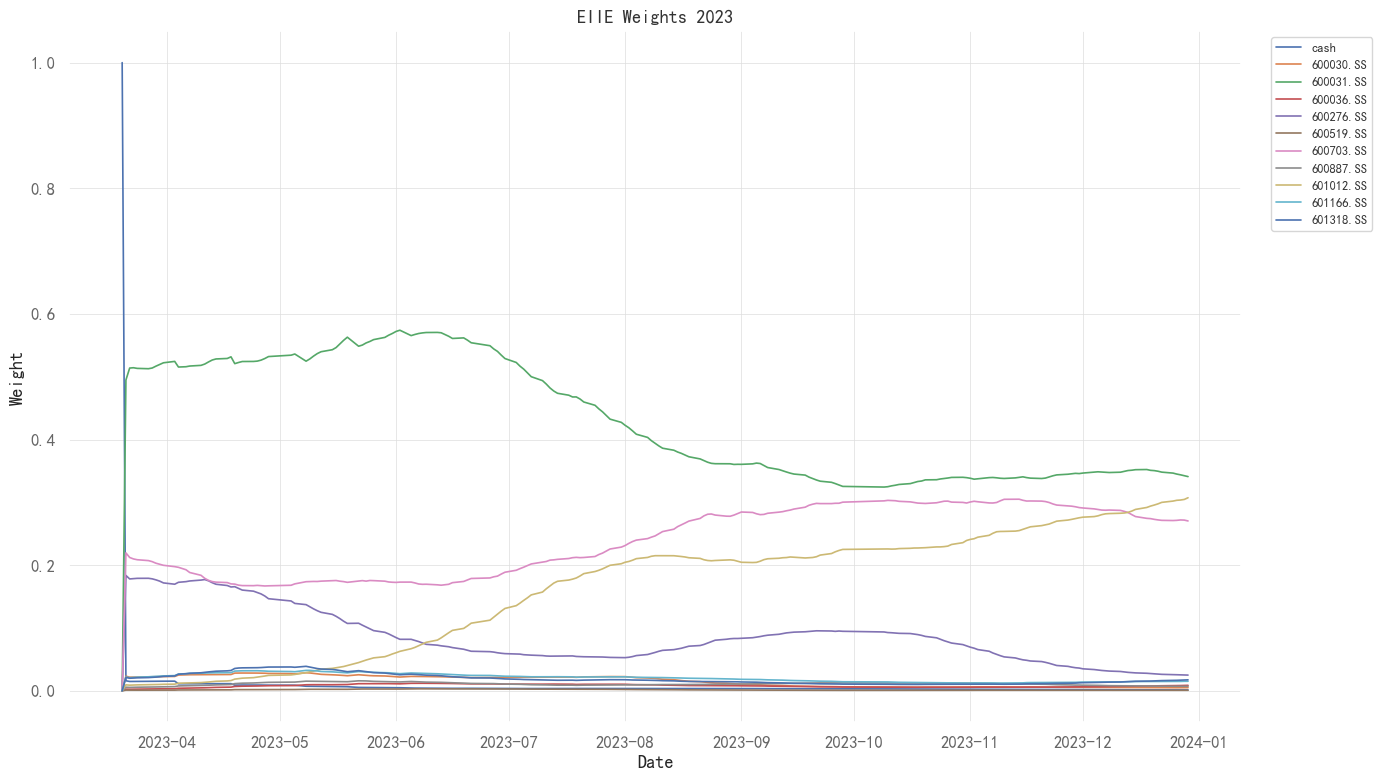

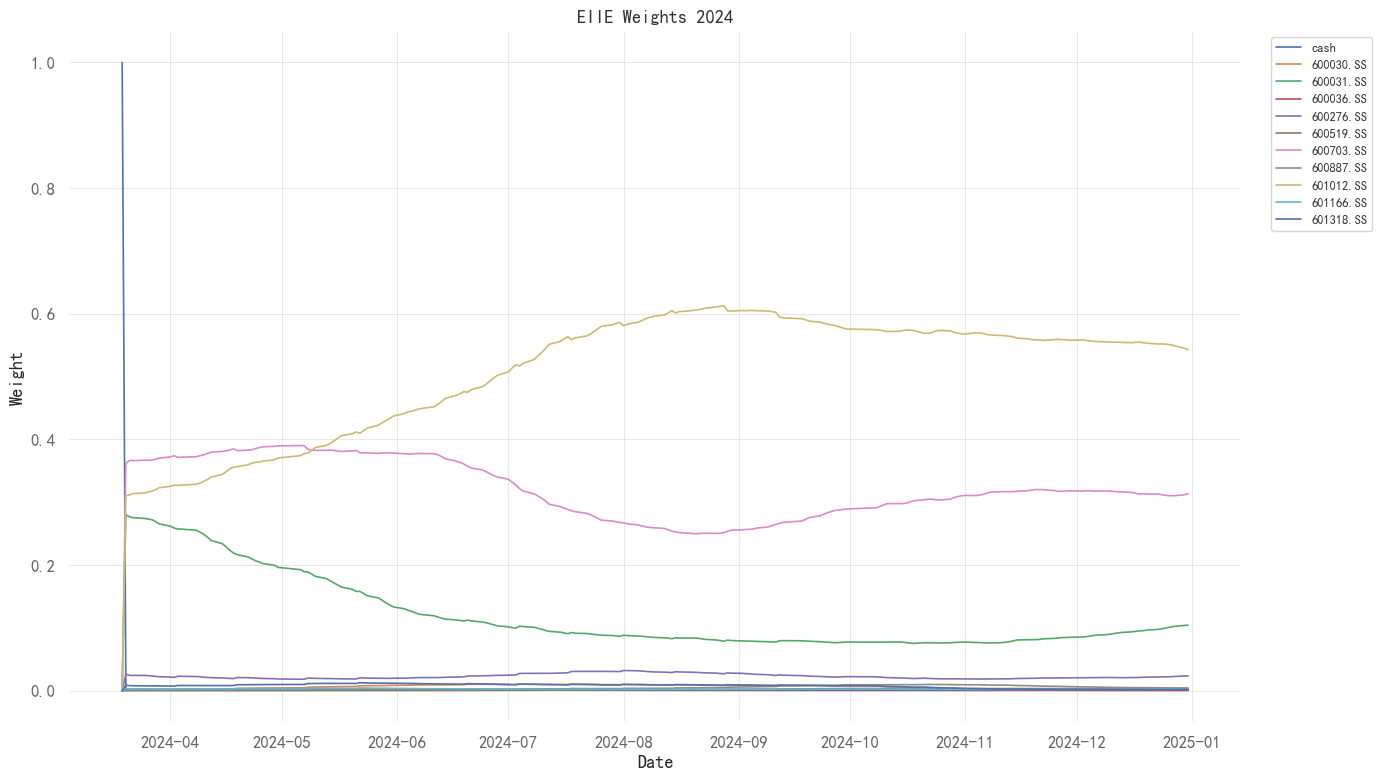

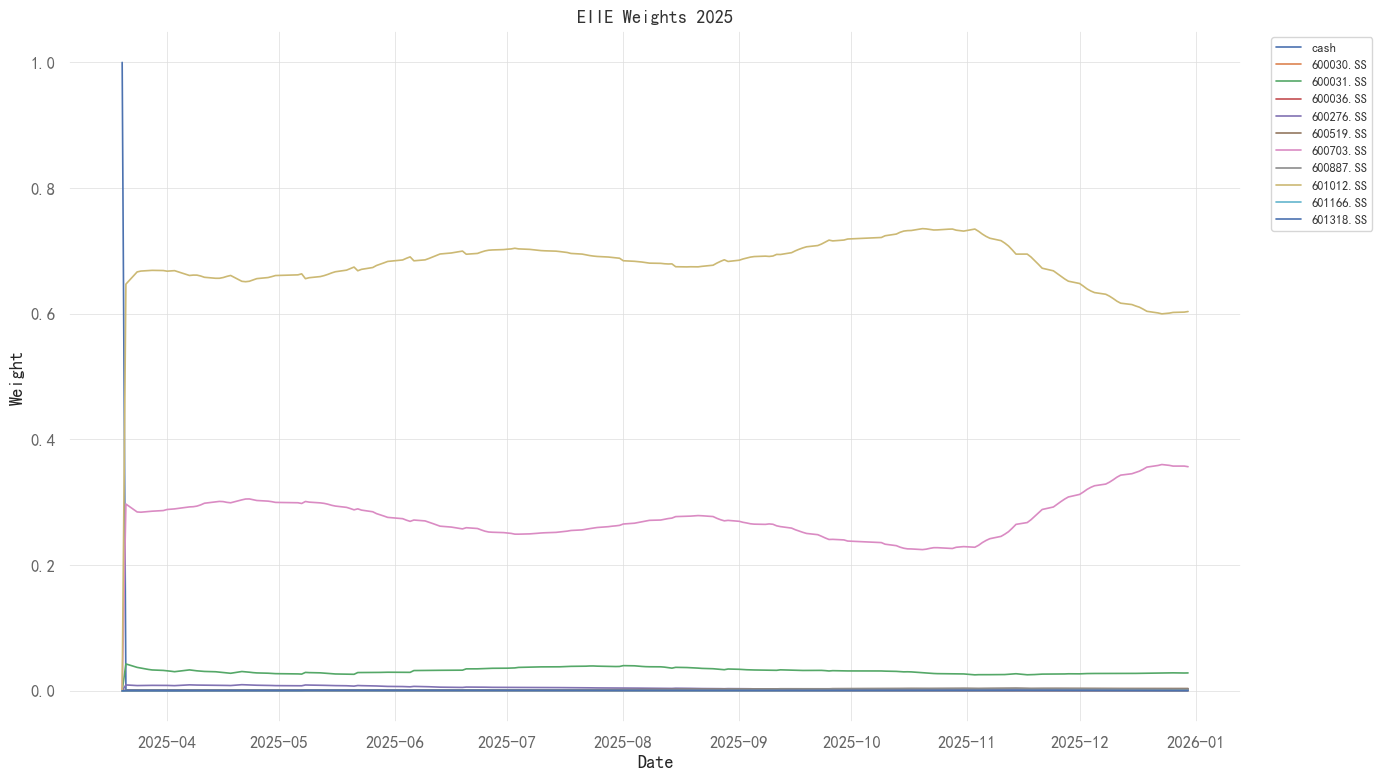

In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# def plot_actions(actions, raw_df, title, save_path=None):
#     actions = np.asarray(actions, dtype=np.float32)

#     dates = sorted(pd.to_datetime(raw_df["date"]).unique())
#     n_steps = actions.shape[0]
#     x_dates = dates[-n_steps:] if len(dates) >= n_steps else np.arange(n_steps)

#     tics = sorted(raw_df["tic"].unique().tolist())
#     labels = ["cash"] + tics if actions.shape[1] == len(tics) + 1 else [f"asset_{i}" for i in range(actions.shape[1])]

#     plt.figure(figsize=(14, 8))
#     for i in range(actions.shape[1]):
#         plt.plot(x_dates, actions[:, i], linewidth=1.2, label=labels[i])

#     plt.xlabel("Date")
#     plt.ylabel("Weight")
#     plt.title(title)
#     plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
#     plt.tight_layout()

#     if save_path:
#         plt.savefig(save_path, dpi=300, bbox_inches="tight")
#     plt.show()

# plot_actions(EIIE_results["2023"]["actions"], df_portfolio_2023, "EIIE Weights 2023")
# plot_actions(EIIE_results["2024"]["actions"], df_portfolio_2024, "EIIE Weights 2024")
# plot_actions(EIIE_results["2025"]["actions"], df_portfolio_2025, "EIIE Weights 2025")


### Action figures

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

def plot_actions_pretty(
    actions,
    raw_df,
    title,
    save_path=None,
    top_k=11,
    figsize=(15, 8),
    highlight_cash=True,
):
    actions = np.asarray(actions, dtype=np.float32)

    # 1. 构造横轴日期
    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = dates[-n_steps:] if len(dates) >= n_steps else np.arange(n_steps)

    # 2. 构造标签
    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    # 3. 计算平均权重，用于突出 top_k
    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    # 若有 cash，则默认不把 cash 算进 top_k 股票高亮
    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = stock_idx[:top_k]
    else:
        cash_idx = None
        highlight_idx = sorted_idx[:top_k]

    # 4. 开始画图
    fig, ax = plt.subplots(figsize=figsize)

    # 淡化非重点资产
    for i in range(actions.shape[1]):
        if i == cash_idx:
            continue
        if i in highlight_idx:
            ax.plot(
                x_dates,
                actions[:, i],
                linewidth=2.0,
                alpha=0.95,
                label=labels[i]
            )
        else:
            ax.plot(
                x_dates,
                actions[:, i],
                linewidth=0.9,
                alpha=0.18,
                color="gray"
            )

    # 单独强调 cash
    if cash_idx is not None:
        ax.plot(
            x_dates,
            actions[:, cash_idx],
            linewidth=2.6,
            linestyle="--",
            color="black",
            alpha=0.9,
            label="cash"
        )

    # 5. 坐标轴与格式
    ax.set_title(title, fontsize=16, pad=12)
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("Portfolio Weight", fontsize=12)
    ax.set_ylim(-0.02, 1.02)

    # 日期轴格式化
    if isinstance(x_dates[0], (np.datetime64, pd.Timestamp)):
        locator = mdates.AutoDateLocator()
        formatter = mdates.ConciseDateFormatter(locator)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(formatter)

    # 网格和边框
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 只展示高亮资产 + cash 的图例
    handles, legend_labels = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=min(4, len(legend_labels)),
        frameon=False,
        fontsize=10
    )

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

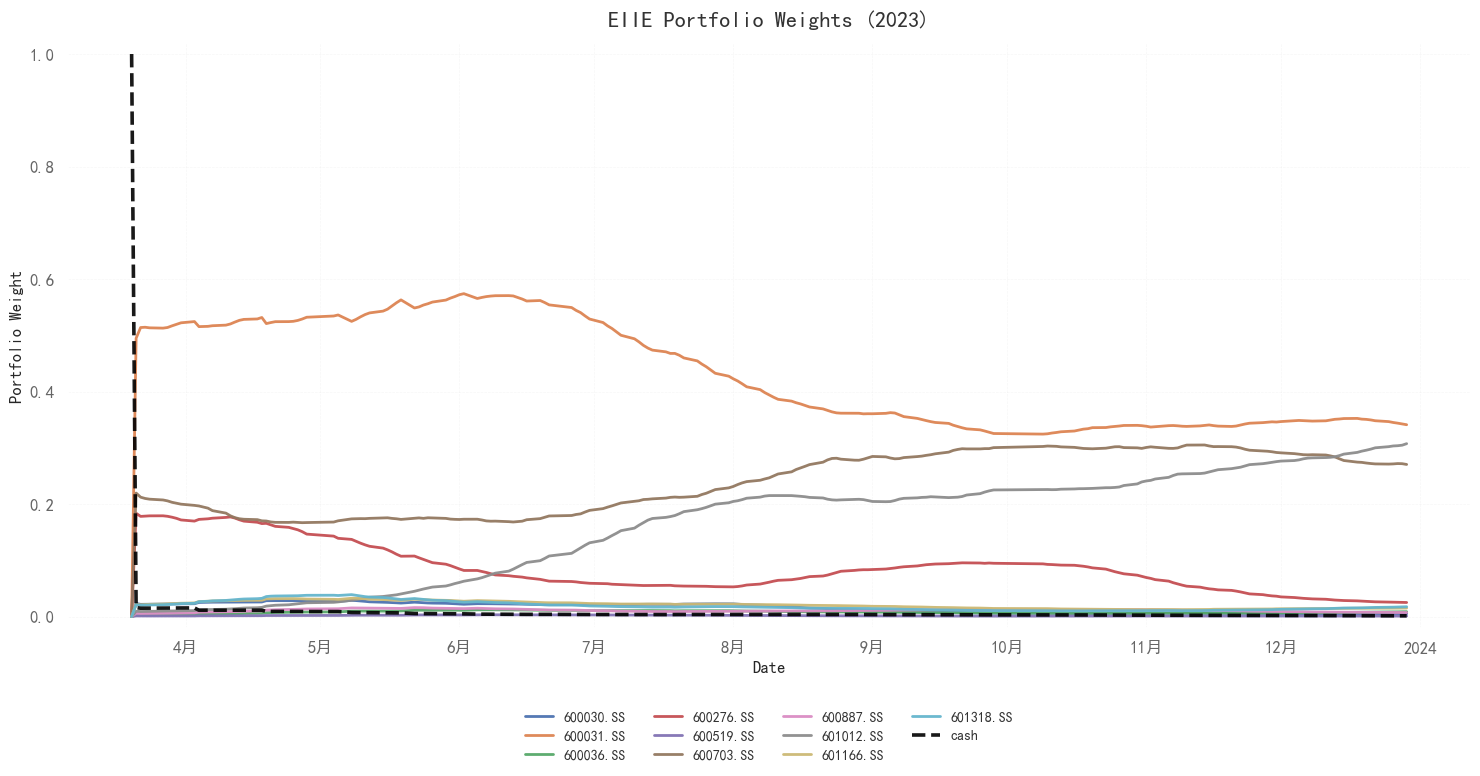

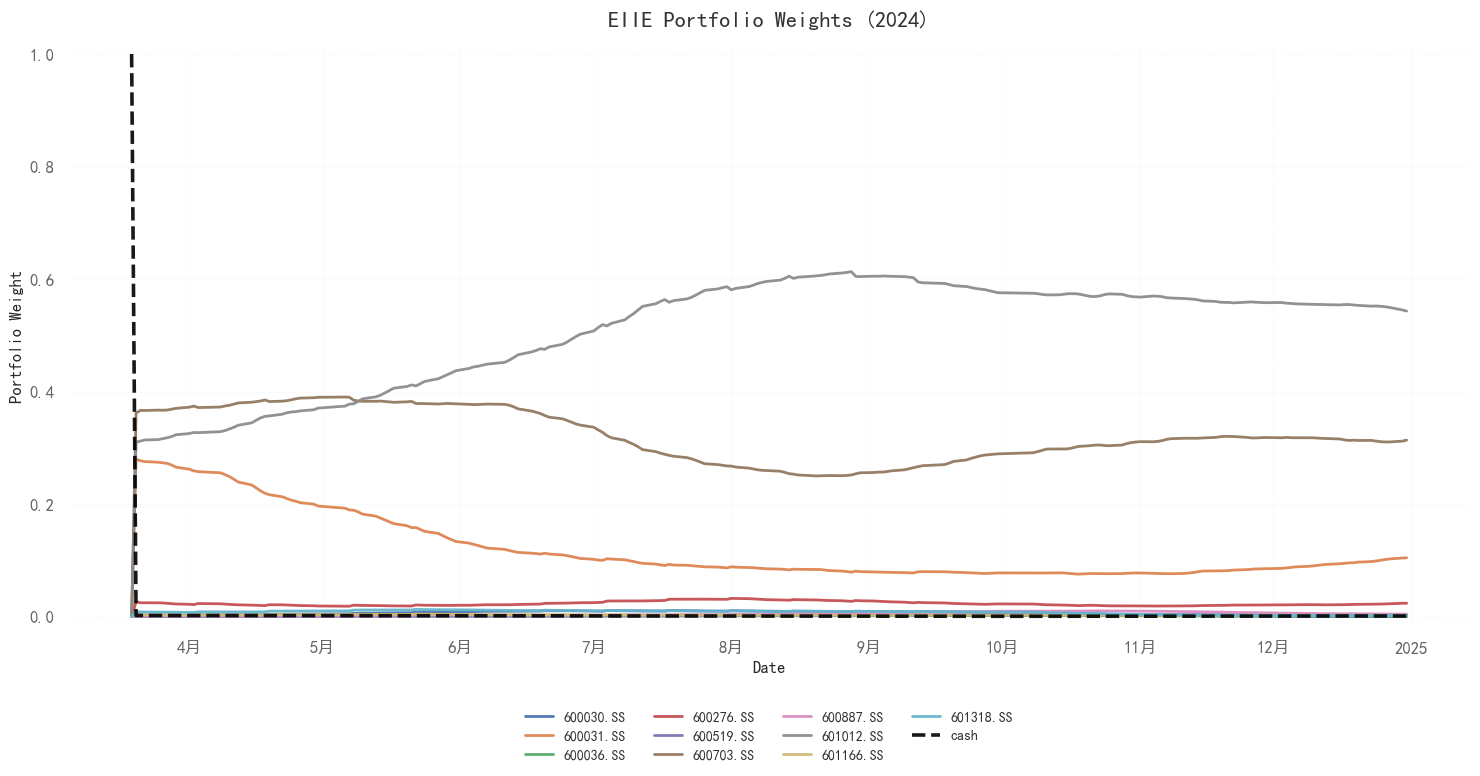

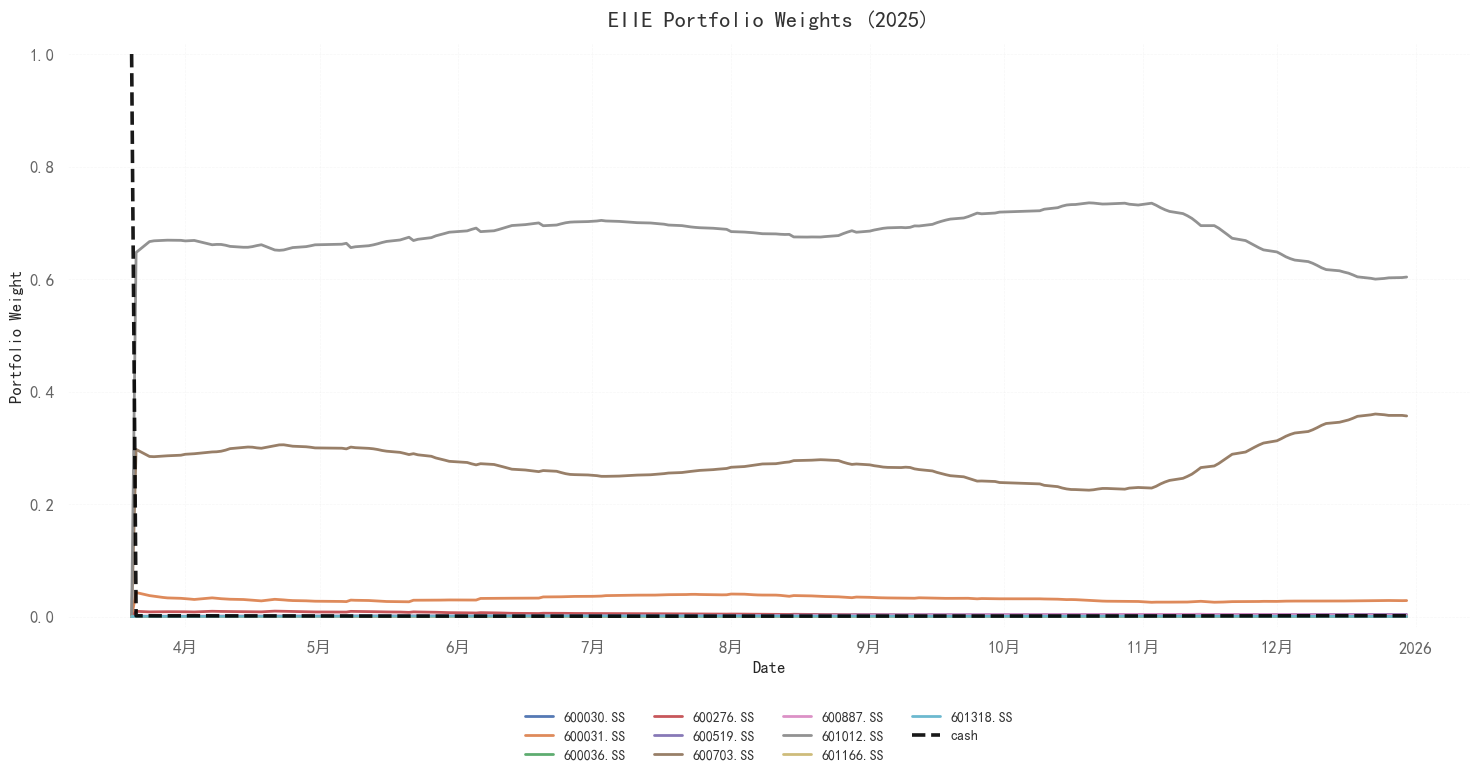

In [ ]:
output_dir = "raw_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plot_actions_pretty(
    EIIE_results["2023"]["actions"],
    df_portfolio_2023,
    "EIIE Portfolio Weights (2023)",
    save_path=os.path.join(output_dir, "EIIE_weights_2023.png"),
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2024"]["actions"],
    df_portfolio_2024,
    "EIIE Portfolio Weights (2024)",
    save_path=os.path.join(output_dir, "EIIE_weights_2024.png"),
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2025"]["actions"],
    df_portfolio_2025,
    "EIIE Portfolio Weights (2025)",
    save_path=os.path.join(output_dir, "EIIE_weights_2025.png"),
    top_k=11
)